## Stats and Plotting

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path
import random
import json
import csv
from collections import Counter
from global_land_mask import globe
import h3
import seaborn as sns
plt.style.use('ggplot')

In [17]:
# Global vars single species
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
INPUT_COLS = ["sin_lon", "cos_lon", "sin_lat", "cos_lat"]
NUM_INPUTS = len(INPUT_COLS)
NUM_EPOCHS = 11
LEARNING_RATE = 5e-3
CRITERION = nn.BCEWithLogitsLoss(reduction='none') #reduction = none prevents the batch average, preserves shape.
BATCH_SIZE = 512
NUM_HIDDEN_LAYERS = 3
HIDDEN_DIM = 128
RESULTS_DIR = Path.cwd()
COMMON_SETTINGS = {
    'seed': SEED, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'num_epochs': NUM_EPOCHS,
}
LABEL_SMOOTHING = 0.0
DROPOUT_KEEP = 0.85

In [24]:
class MultiSpeciesMLP(nn.Module):
    def __init__(
            self, num_species=500, num_inputs=NUM_INPUTS,
            num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM,
            activation=nn.ReLU, dropout_keep=DROPOUT_KEEP):
        
        super().__init__()
        self.num_inputs = num_inputs
        self.num_hidden_layers = num_hidden_layers
        self.hidden_dim = hidden_dim
        
        layers = []
        input_dim = num_inputs
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(input_dim, hidden_dim))
            if dropout_keep is not None:
                layers.append(nn.Dropout(p=1.0 - dropout_keep))
            layers.append(activation())
            input_dim = hidden_dim

        layers.append(nn.Linear(input_dim, num_species))
        self.model = nn.Sequential(*layers)
        for layer in self.model.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, inputs):
        return self.model(inputs)

class SingleSpeciesMLP(nn.Module):
    def __init__(
            self, num_species=500, num_inputs=NUM_INPUTS,
            num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM, embedding_dim=32,
            activation=nn.ReLU, dropout_keep=DROPOUT_KEEP):
        
        super().__init__()
        self.num_inputs = num_inputs
        self.num_hidden_layers = num_hidden_layers
        self.hidden_dim = hidden_dim
        self.species_embed = nn.Embedding(num_species, embedding_dim)

        layers = []
        input_dim = num_inputs + embedding_dim
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(input_dim, hidden_dim))
            if dropout_keep is not None:
                layers.append(nn.Dropout(p=1.0 - dropout_keep))
            layers.append(activation())
            input_dim = hidden_dim

        layers.append(nn.Linear(input_dim, 1))
        self.model = nn.Sequential(*layers)
        for layer in self.model.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, inputs):
        input_feats = inputs[:, :self.num_inputs]
        species_idx = inputs[:, self.num_inputs].to(torch.long)
        species_emb = self.species_embed(species_idx)
        inputs_emb = torch.cat([input_feats, species_emb], dim=-1)
        return self.model(inputs_emb).squeeze(-1)



In [25]:
# Tained Model Inference
def multi_species_predict(model, input, batch_size=1024):
    model.eval()
    device = DEVICE
    prob = []

    with torch.no_grad():
        for i in range(0, len(input), batch_size):
            input_tens = torch.tensor(input[i : i+batch_size], dtype=torch.float32, device=device)
            prob.append(torch.sigmoid(model(input_tens)).cpu().detach().numpy())

    return np.vstack(prob)

def single_species_predict_test(model, input, batch_size=1024):
    model.eval()
    device = DEVICE
    examples = len(input)
    probs = np.zeros((examples, 500))
    input_tens = torch.as_tensor(input, dtype=torch.float32, device=DEVICE)
     
    with torch.no_grad():
        for species in range(500):
            species_col = torch.full((examples, 1), species, dtype=torch.float32, device=DEVICE)
            species_in = torch.cat([input_tens, species_col], dim=1)
            species_prob = []
            for i in range(0, examples, batch_size):
                species_prob.append(torch.sigmoid(model(species_in[i : i + batch_size])).cpu().numpy().reshape(-1))
            probs[:, species] = np.concatenate(species_prob)
    return probs

    

In [36]:


# Per species metrics

def per_species_metrics_multi(probs, targets, thresholds, mask=None):
    stored_metrics = ('roc_auc', 'ave_pre', 'tss', 'sensitivity', 'specificity')
    metrics = {keys: np.full(500, np.nan) for keys in stored_metrics}
    conf_mat_plot = 500 * [None]

    for species in range(500):
        if mask is not None:
            mask_m = mask[:, species].astype(bool)
            targs = targets[mask_m, species].astype(int)
            probs_p = probs[mask_m, species]
        else:
            targs = targets[:, species].astype(int)
            probs_p = probs[:, species]
        if len(np.unique(targs)) < 2:
            continue

        predicts = (probs_p >= thresholds[species]).astype(int)
        conf_mat_plot[species] = ConfusionMatrixDisplay(confusion_matrix(targs, predicts, labels=[0, 1]), display_labels=['Absence = 0', 'Presence = 1'])
        tru_neg, fal_pos, fal_neg, tru_pos = confusion_matrix(targs, predicts, labels=[1, 0]).ravel()

        sensitivity = tru_pos / (tru_pos + fal_neg)
        specificity = tru_neg / (tru_neg + fal_pos)

        
        metrics['roc_auc'][species] = roc_auc_score(targs, probs_p)
        metrics['ave_pre'][species] = average_precision_score(targs, probs_p)
        metrics['tss'][species] = sensitivity + specificity - 1.0
        metrics['sensitivity'][species] = sensitivity
        metrics['specificity'][species] = specificity

    return metrics, conf_mat_plot




In [27]:
# Presence absence output
def presence_absence_multi(model, inputs, thresholds):
    probs = multi_species_predict(model, inputs)
    pres_abs = (probs >= thresholds).astype(int)
    
    return pres_abs

def presence_absence_single_test(model, inputs, thresholds):
    probs = single_species_predict_test(model, inputs)
    pres_abs = (probs >= thresholds).astype(int)
    
    return pres_abs, probs


### preprocess_test.py

In [22]:
import numpy as np
import h3
import pandas as pd

test = np.load('species/species_test.npz', allow_pickle=True)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

res = 4
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
cell_index = {c: i for i, c in enumerate(grid_cells)}
cell_test= []
for lat, lon in test['test_locs'].astype(float):
    cell_test.append(cell_index[h3.latlng_to_cell(lat, lon, res)])
cell_test = np.array(cell_test)

X_test = encode(test['test_locs'])
y_test = np.zeros((len(X_test), len(test['taxon_ids'])), dtype=bool)
for i, pos in enumerate(test['test_pos_inds']):
    y_test[pos, i] = 1  # species i present at these locations, 0 elsewhere

print('X_test-', X_test.shape, ', y_test-', y_test.shape, ', cell_test-', cell_test.shape)

# Save
np.savez('species/preprocessed_cells_test.npz', X_test=X_test, y_test=y_test, cell_test=cell_test, test_locs=test['test_locs'], taxon_ids=test['taxon_ids'])

# Usage for models
preprocessed = np.load('species/preprocessed_cells_test.npz')
cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']
test_df = pd.DataFrame(preprocessed['X_test'], columns=cols)
test_df['cell'] = preprocessed['cell_test']
test_df['n_species'] = preprocessed['y_test'].sum(axis=1)  # number of species present at each point
test_df['species'] = [np.flatnonzero(row) for row in preprocessed['y_test']]

X = preprocessed['X_test']
y = preprocessed['y_test'].astype(np.float32)  # for NN, 0/1 for each test point for all 500 species

print(test_df.head())

X_test- (288122, 4) , y_test- (288122, 500) , cell_test- (288122,)
    sin_lon   cos_lon   sin_lat   cos_lat    cell  n_species          species
0 -0.112586 -0.993642  0.329871  0.944026  134017          3  [162, 252, 384]
1 -0.299965 -0.953950  0.133619  0.991033  133019          3  [162, 252, 384]
2 -0.208854 -0.977947  0.149162  0.988813  132538          3  [162, 252, 384]
3 -0.178451 -0.983949  0.135019  0.990843  132482          3  [162, 252, 384]
4 -0.181306 -0.983427 -0.216004  0.976393  133649          3  [162, 252, 384]


### worlclim_test.py

In [23]:
import numpy as np
import pandas as pd

# Load the climate grid
env_grid = np.load('bioclim_h3_res4.npz')['env_grid']

# Load the preprocessed test cells
preprocessed_test = np.load('species/preprocessed_cells_test.npz')
X_test = preprocessed_test['X_test']
y_test = preprocessed_test['y_test']
cell_test = preprocessed_test['cell_test']

cols = ['sin_lon',
        'cos_lon',
        'sin_lat',
        'cos_lat'
       ]

# Column names
env_cols = ['Annual Mean Temperature',
            'Temperature Seasonality',
            'Max Temperature of Warmest Month',
            'Min Temperature of Coldest Month',
            'Annual Precipitation',
            'Precipitation Seasonality',
            'Precipitation of Driest Quarter',
            'Elevation']

# Make the test df from the preprocessed test cells
test_df_bio = pd.DataFrame(X_test, columns=cols)
test_df_bio['cell'] = cell_test

# climate for each cell
test_df_bio[env_cols] = env_grid[test_df_bio['cell'].values]

# Drop cells with no climate data (ocean)
clean_test = test_df_bio[env_cols].notna().all(axis=1).values
test_df_bio = test_df_bio[clean_test]
X_test_bio = test_df_bio[env_cols].values
X_test_bio_coords = test_df_bio[cols + env_cols].values
X_test_coords = test_df_bio[cols].values
y_test_bio = y_test[clean_test]
cell_test_bio = cell_test[clean_test]

# Save
np.savez('preprocessed_test_bio.npz', X_test=X_test_bio, y_test=y_test_bio, cell_test=cell_test_bio)
print('X_test_bio-', X_test_bio.shape, ', y_test_bio-', y_test_bio.shape)
print('X_test_bio_coords-', X_test_bio_coords.shape, ', y_test_bio-', y_test_bio.shape)
print('X_test_coords-', X_test_coords.shape, ', y_test_bio-', y_test_bio.shape)

X_test_bio- (89377, 8) , y_test_bio- (89377, 500)
X_test_bio_coords- (89377, 12) , y_test_bio- (89377, 500)
X_test_coords- (89377, 4) , y_test_bio- (89377, 500)


In [28]:
# Load models

def load_model(model_object, saved_weigths):
    model = model_object.to(DEVICE)
    model.load_state_dict(torch.load(saved_weigths, map_location=DEVICE))
    model.eval()
    return model

model_dict = {
    'multi_bio_coords': load_model(MultiSpeciesMLP(num_inputs=12), 'multi_sp_depth_3__width_128__inputs_12__epochs_11__dropout_0.85_weights.pt'),
    'multi_bio': load_model(MultiSpeciesMLP(num_inputs=8), 'multi_sp_depth_3__width_128__inputs_8__epochs_22__dropout_0.85_weights.pt'),
    'multi_coords': load_model(MultiSpeciesMLP(num_inputs=4), 'multi_sp_depth_3__width_128__inputs_4__epochs_27__dropout_0.85_weights.pt'),
    'single_bio_coords': load_model(SingleSpeciesMLP(num_inputs=12), 'single_sp_depth_3__width_128__inputs_12__epochs_22__dropout_0.85_weights.pt'),
    'single_bio': load_model(SingleSpeciesMLP(num_inputs=8), 'single_sp_depth_3__width_128__inputs_8__epochs_38__dropout_0.85_weights.pt'),
    'single_coords': load_model(SingleSpeciesMLP(num_inputs=4), 'single_sp_depth_3__width_128__inputs_4__epochs_21__dropout_0.85_weights.pt'),
}


X_test_dict = {
    'multi_bio_coords': X_test_bio_coords,
    'multi_bio': X_test_bio,
    'multi_coords': X_test_coords,
    'single_bio_coords': X_test_bio_coords,
    'single_bio': X_test_bio,
    'single_coords': X_test_coords,
}

thresholds_dict = {
    'multi_bio_coords': np.load('thresholds_multi_bio_coords.npz')['thresholds'],
    'multi_bio': np.load('thresholds_multi_bio.npz')['thresholds'],
    'multi_coords': np.load('thresholds_multi_coords.npz')['thresholds'],
    'single_bio_coords': np.load('thresholds_single_bio_coords.npz')['thresholds'],
    'single_bio': np.load('thresholds_single_bio.npz')['thresholds'],
    'single_coords': np.load('thresholds_single_coords.npz')['thresholds'],
}

probs_dict = {}
pres_abs_dict = {}

for name, model in model_dict.items():
    X_test = X_test_dict[name]
    thresholds = thresholds_dict[name]  # Added lookup using the same key
    
    if name.startswith('multi'):
        probs_dict[name] = multi_species_predict(model, X_test)
        pres_abs_dict[name] = presence_absence_multi(model, X_test, thresholds)
    else:
        probs_dict[name] = single_species_predict_test(model, X_test)
        pres_abs_dict[name] = presence_absence_single_test(model, X_test, thresholds)




C:\Users\sebas\AppData\Local\Temp\ipykernel_29340\1454373921.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  input_tens = torch.as_tensor(input, dtype=torch.float32, device=DEVICE)


In [30]:
np.savez('neural_network_test_probs.npz', **probs_dict)
np.savez('neural_network_test_pres_abs.npz', **pres_abs_dict)

In [31]:
loaded_probs_dict = dict(np.load('neural_network_test_probs.npz'))
loaded_pres_abs_dict = dict(np.load('neural_network_test_pres_abs.npz'))

In [39]:
print(probs_dict.keys())

dict_keys(['multi_bio_coords', 'multi_bio', 'multi_coords', 'single_bio_coords', 'single_bio', 'single_coords'])


In [40]:
tax_class_names = {0: 'Amphibia', 1: 'Aves', 2: 'Crocodylia', 3: 'Mammalia', 4: 'Squamata', 5: 'Testudines'}
metric_keys = ['roc_auc', 'ave_pre', 'tss', 'sensitivity', 'specificity']
prepro_sp = np.load('species/preprocessed_species.npz')
taxons = prepro_sp['taxon_ids']
ids = prepro_sp['id']
classes = prepro_sp['class_id']
# Number for each class 
# {0: 'Amphibia', 1: 'Aves', 2: 'Crocodylia', 3: 'Mammalia', 4: 'Squamata', 5: 'Testudines'}
species_to_class = np.full(500, 10)
species_to_class[ids] = classes
macro_rows = []
class_rows = []
#conf_matrices = {} 



for name, probs in probs_dict.items(): 
    thresholds = thresholds_dict[name]
    metrics, conf_mat = per_species_metrics_multi(probs, y_test_bio, thresholds=thresholds) 
    #conf_matrices[name] = conf_mat
        
    macro_row = {'model': name}
    for keys in metric_keys:
        macro_row[keys] = np.mean(metrics[keys])
    macro_rows.append(macro_row)

    per_class_metrics = {}

    for cl in range(6):
        class_mask = (species_to_class == cl)
        species_count = int(class_mask.sum())
        if species_count == 0:
            continue
        class_metrics = {'species_count': species_count}
        for keys, vals in metrics.items():
            vals_in_class = vals[class_mask]
            mean_val = np.mean(vals_in_class)
            class_metrics[keys] = mean_val
        per_class_metrics[cl] = class_metrics
    
    for i, class_name in tax_class_names.items():
        class_row = {
            'model': name,
            'tax_class': class_name,
            'species_count': per_class_metrics[i]['species_count']
        }
        for keys in metric_keys:
            class_row[keys] = np.nanmean(per_class_metrics[i][keys])
        class_rows.append(class_row)


df_macro_metrics = pd.DataFrame(macro_rows)
df_per_class_metrics = pd.DataFrame(class_rows)

In [41]:
df_macro_metrics.to_csv('model_macro_metrics.csv', index=False)
df_per_class_metrics.to_csv('model_per_class_metrics.csv', index=False)

In [56]:
df_macro_metrics = pd.read_csv('model_macro_metrics.csv')
df_per_class_metrics = pd.read_csv('model_per_class_metrics.csv')

In [128]:
def get_taxon_id(species_id, taxons=taxons):
    taxon_id = int(taxons[species_id])
    print(f"species_id {species_id} -> taxon_id {taxon_id}")

def get_species_id(taxon_id, taxons=taxons):
    map = np.where(taxons == taxon_id)[0]
    species_id = int(map[0])
    print(f"taxon_id {taxon_id} -> species_id {species_id}")


get_taxon_id(414)
get_species_id(560425)

species_id 414 -> taxon_id 7562
taxon_id 560425 -> species_id 287


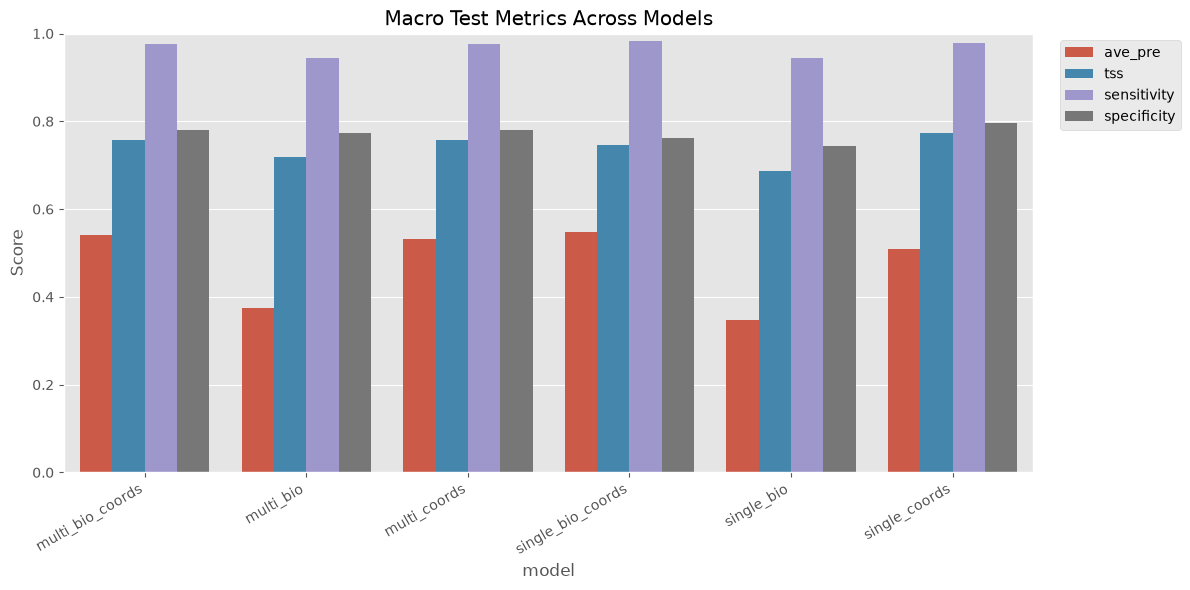

In [57]:

df_macro_melted = df_macro_metrics.drop(columns=['roc_auc']).melt(id_vars='model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_macro_melted, x='model', y='Score', hue='Metric')
plt.title('Macro Test Metrics Across Models')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('macro_metrics_comparison.png', dpi=300)
plt.show()

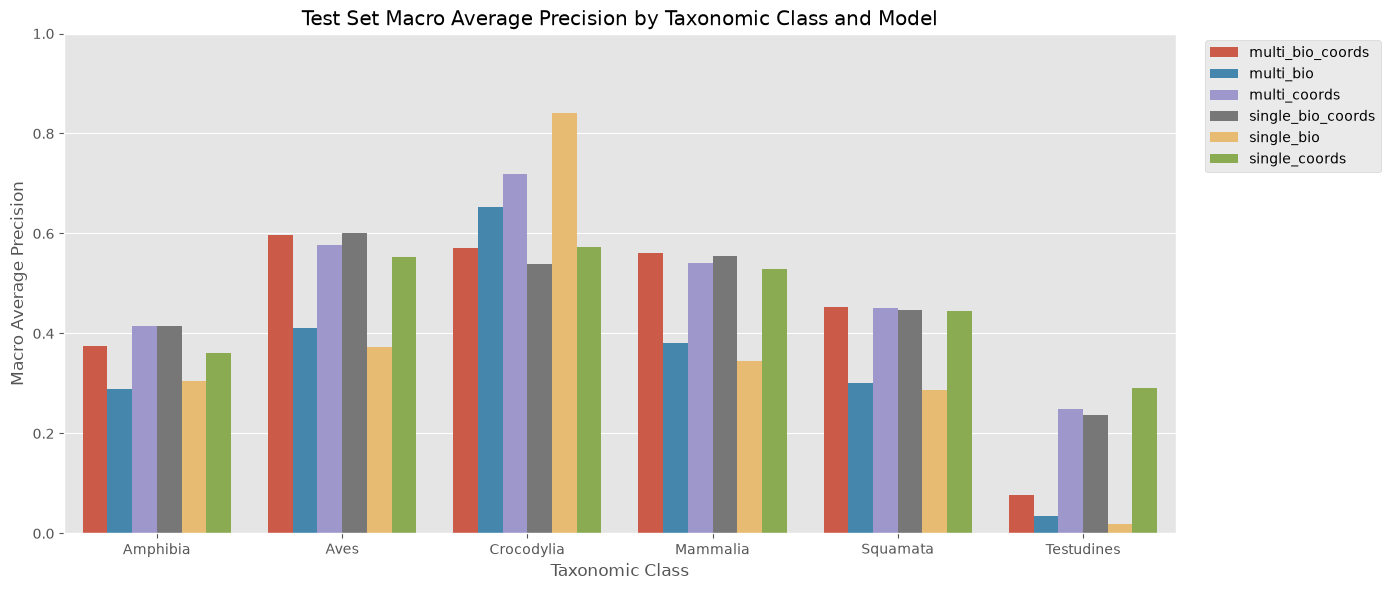

In [58]:
plt.figure(figsize=(14, 6))
sns.barplot(data=df_per_class_metrics, x='tax_class', y='ave_pre', hue='model')
plt.title('Test Set Macro Average Precision by Taxonomic Class and Model')
plt.xlabel('Taxonomic Class')
plt.ylabel('Macro Average Precision')
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('per_class_roc_auc.png', dpi=300)
plt.show()